/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_17390/2385713641.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Method'] = df['Method'].map(proper_method_names).fillna(df['Method'])
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_17390/2385713641.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Method'] = df['Method'].map(proper_method_names).fillna(df['Method'])
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_17390/2385713641.py:64: SettingWithCopyWarning:

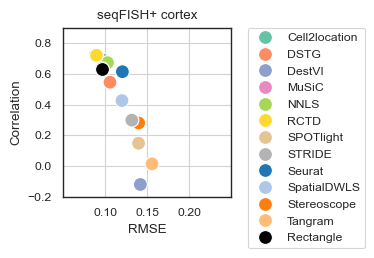

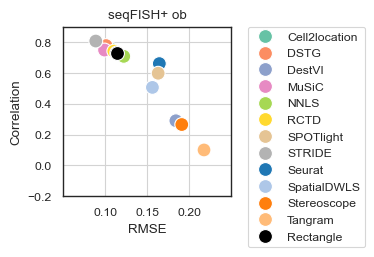

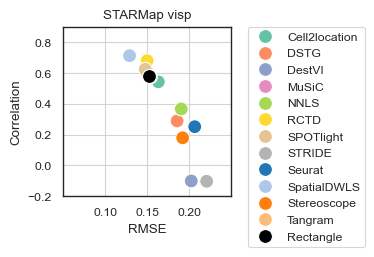

In [3]:
import re
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator


base_dir = Path("../data/fig5")
datasets = ["Eng2019_cortex_svz", "Eng2019_ob", "Wang2018_visp"]

rows = []
for dataset in datasets:
    dataset_dir = base_dir / dataset
    if dataset == "Wang2018_visp":
        pattern = re.compile(r"metrics_(.+)_Wang2018_visp_.*$")
        glob_pattern = "metrics_*_Wang2018_visp_*"
    else:
        pattern = re.compile(rf"metrics_(.+)_{re.escape(dataset)}_fov\d+$")
        glob_pattern = f"metrics_*_{dataset}_fov*"

    for path in sorted(dataset_dir.glob(glob_pattern)):
        match = pattern.match(path.name)
        if not match:
            continue
        method = match.group(1)
        df = pd.read_csv(path, sep=r"\s+", engine="python")
        df.columns = [c.strip('"') for c in df.columns]
        rows.append({
            "Set": dataset,
            "Method": method,
            "Correlation": float(df.loc[0, "corr"]),
            "RMSE": float(df.loc[0, "RMSE"]),
        })

all_meths = pd.DataFrame(rows)
all_meths = (
    all_meths.groupby(["Set", "Method"], as_index=False)
    .agg({"Correlation": "mean", "RMSE": "mean"})
)

all_meths_cortex = all_meths[all_meths['Set'] == 'Eng2019_cortex_svz']
all_meths_ob = all_meths[all_meths['Set'] == 'Eng2019_ob']
all_meths_visp = all_meths[all_meths['Set'] == 'Wang2018_visp']

proper_method_names = {
    "spotlight": "SPOTlight",
    "music": "MuSiC",
    "cell2location": "Cell2location",
    "rctd": "RCTD",
    "stereoscope": "Stereoscope",
    "spatialdwls": "SpatialDWLS",
    "destvi": "DestVI",
    "nnls": "NNLS",
    "dstg": "DSTG",
    "seurat": "Seurat",
    "tangram": "Tangram",
    "stride": "STRIDE",
    "rectangle": "Rectangle"
}

for df in (all_meths_cortex, all_meths_ob, all_meths_visp):
    df['Method'] = df['Method'].map(proper_method_names).fillna(df['Method'])

methods = sorted(all_meths['Method'].unique())
if 'rectangle' in methods:
    methods = [m for m in methods if m != 'rectangle'] + ['rectangle']
methods_display = [proper_method_names.get(m, m) for m in methods]

# alphabetical order for legend, rectangle last
methods_display_no_rect = sorted([m for m in methods_display if m != 'Rectangle'])
methods_display = methods_display_no_rect + ['Rectangle']

# build a palette that scales beyond Set2
base_colors = sns.color_palette("Set2")
needed = len(methods_display_no_rect)
if needed <= len(base_colors):
    colors = base_colors[:needed]
else:
    extra = sns.color_palette("tab20", n_colors=needed - len(base_colors))
    colors = base_colors + extra

palette_display = dict(zip(methods_display_no_rect, colors))
palette_display['Rectangle'] = '#000000'

sns.set_theme(style="white", context="paper")


def plot_dataset(df, title, out_path):
    plt.figure(figsize=(2.5, 2.6))

    # base plot for legend
    sns.scatterplot(
        data=df,
        x='RMSE',
        y='Correlation',
        hue='Method',
        hue_order=methods_display,
        s=100,
        palette=palette_display
    )

    # overlay rectangle last for visibility
    df_rectangle = df[df['Method'] == 'Rectangle']
    if not df_rectangle.empty:
        sns.scatterplot(
            data=df_rectangle,
            x='RMSE',
            y='Correlation',
            hue='Method',
            hue_order=['Rectangle'],
            s=100,
            palette=palette_display,
            legend=False,
            zorder=10
        )

    plt.title(title)
    plt.ylim(-0.2, 0.9)
    plt.xlim(0.05, 0.25)
    plt.xticks([0.1,0.15, 0.2])

    ax = plt.gca()  # <-- define ax here

    # optional: faint minor grid
    ax.grid(which='major', linestyle='-', color='lightgrey')
    plt.tight_layout()
    plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()

plot_dataset(all_meths_cortex, 'seqFISH+ cortex', '../figures/fig5c_Eng2019_cortex_svz.pdf')
plot_dataset(all_meths_ob, 'seqFISH+ ob', '../figures/fig5c_Eng2019_ob.pdf')
plot_dataset(all_meths_visp, 'STARMap visp', '../figures/fig5c_Wang2018_visp_12celltypes.pdf')


##  5b

In [3]:
## 5b

In [8]:
import spatialdata_io
import pandas as pd
import numpy as np
from anndata import AnnData, read_h5ad
import rectanglepy as rectangle

s_data = spatialdata_io.visium(path='../data/spatial_ST8059048', dataset_id='ST8059048', scalefactors_file='scalefactors_json.json', tissue_positions_file='tissue_positions_list.csv', counts_file='ST8059048_filtered_feature_bc_matrix.h5')



INFO     reading ../data/spatial_ST8059048/ST8059048_filtered_feature_bc_matrix.h5                                 


/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/spatialdata/models/models.py:1144: UserWarning: Converting `region_key: region` to categorical dtype.
  return convert_region_column_to_categorical(adata)


In [9]:
adata = read_h5ad('../data/cell2location_single_cell_processed.h5ad')


In [10]:
adata.obs['annotation_1'].value_counts()


annotation_1
Oligo_2           5859
Inh_4              830
Ext_L23            801
Ext_Thal_1         740
Micro              726
Ext_L56            645
Ext_L25            596
Ext_Pir            592
OPC_1              533
Ext_Hpc_DG2        523
Ext_L5_1           510
Inh_1              484
Inh_Pvalb          441
Ext_Hpc_CA1        426
Inh_2              420
Inh_3              414
Ext_Amy_2          406
Ext_Thal_2         383
Inh_Meis2_3        365
Inh_Sst            330
Inh_Vip            285
Oligo_1            285
Ext_L6             281
Inh_Meis2_2        275
Inh_6              264
Astro_THAL_med     243
Ext_Hpc_DG1        240
Astro_CTX          233
Astro_HYPO         232
Astro_AMY_CTX      209
Inh_Meis2_1        207
Ext_Amy_1          190
Astro_AMY          188
Inh_Lamp5          179
Ext_L6B            171
Astro_THAL_lat     168
OPC_2              159
Ext_Hpc_CA3        140
Ext_ClauPyr        131
Astro_HPC          130
Nb_1               126
Astro_WM           124
Ext_L5_2           11

adata.obs.value_counts()

In [11]:
data_table = s_data['table']
bulks = data_table.to_df()
bulks_cpm = bulks.div(bulks.sum(axis=1), axis=0) * 1e6

In [ ]:
estimations, signature_result = rectangle.rectangle(adata, bulks_cpm)


2026-05-13 13:16:13.030 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 19788 common genes between bulks and single-cell data
2026-05-13 13:16:16.036 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/pp/create_signature.py:181: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bootstrapped_signature[f"{celltype}_{i}"] = list(summed_rows)
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/pp/create_signature.py:181: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  C

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-05-13 13:17:07.388 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:416 - RMSE:0.024473209724155984, Pearson R:0.45407791950549475 for p=0.05, lfc=1.6


Polishing not needed - no active set detected at optimal point


2026-05-13 13:17:07.814 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 41


...

2026-05-13 13:17:13.540 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 46


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-05-13 13:17:13.837 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:416 - RMSE:0.026170724143207688, Pearson R:0.43162642627748093 for p=0.05, lfc=2.2
2026-05-13 13:17:13.839 | INFO     | rectanglepy.pp.create_signature:_de_analysis:208 - Optimization done
 Best cutoffs  p: 0.05 and lfc: 1.6
2026-05-13 13:17:14.111 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 79
2026-05-13 13:17:14.137 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:348 - Starting rectangle cluster analysis
2026-05-13 13:17:14.155 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:266 - Starting clustered analysis
2026-05-13 13:17:14.674 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/rectanglepy/pp/create_signature.py:181: PerformanceWarning: DataFrame is highly fragmented.  This is usually t

Polishing not needed - no active set detected at optimal point


2026-05-13 13:43:40.812 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 778
2026-05-13 13:43:40.881 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 788
2026-05-13 13:43:43.858 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 782
2026-05-13 13:43:43.859 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 779
2026-05-13 13:43:43.884 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 789
2026-05-13 13:43:43.891 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 790
2026-05-13 13:43:44.245 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:285 - Finished deconvolution for bulk: 780
2026-05-13 13:43:44.296 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:282 - Deconvolute fractions for bulk: 791
2026-05-13 13:43:47.

In [ ]:
# remove disconnected spots
disconnected_spots = ["AATCGAGGTCTCAAGG-1", "ACCACACGGTTGATGG-1",
                   "ACCGAGTCTCCTTATT-1", "AGCAGTCGAAGCATGC-1",
                   "AGTACAGAAGCTTATA-1", "CCTACAGTTGAGGGAG-1",
                   "CGCTTTCCGCCAAGGT-1", "CGGTATGGGCACTCTG-1",
                   "CGGTTGGGCAGGGTCC-1", "CTATCACAACGCTGGA-1",
                   "CTCTAACACCGGCAGC-1", "CTTACATAGATTTCTT-1",
                   "CTTCATCACCAGGGCT-1", "GAAGGGTCATTAAGAC-1",
                   "GACCACACTTCCCTTT-1", "GCACGCCGATTCCCGC-1",
                   "GCGGCTTTAGCAAGTT-1", "GCGTCGTAACATGGTC-1",
                   "GGATTAATCATGGACC-1", "GTACTACGGCCTCGTT-1",
                   "TACACAGCCGTGGTGC-1", "TCAGCGCACGCCGTTT-1",
                   "TGCCCGATAGTTAGAA-1", "TGTAGCCAATTCCGTT-1"]
estimations = estimations.drop(index=disconnected_spots)

In [ ]:
estimations.to_csv('../data/fig5/rectangle_ST8059048_estimations.csv')